In [1]:
pip install numpy matplotlib scikit-image

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import io
from google.colab import drive

drive.mount('/content/drive')

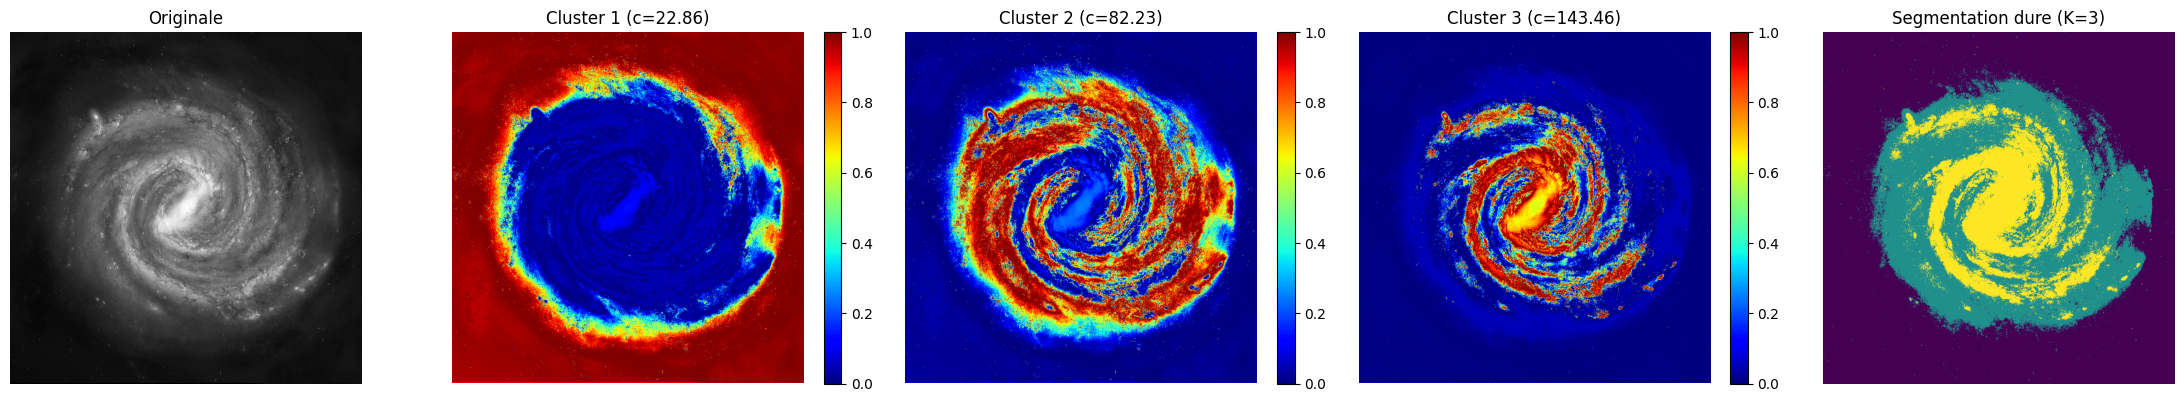

In [15]:
image_path = "/content/drive/MyDrive/milky-way-nvg.jpg"
K = 3

img = io.imread(image_path, as_gray=True)
H, W = img.shape
X = img.reshape(-1, 1)

def fuzzy_c_means(X, K=2, m=2.0, max_iter=50, epsilon=1e-4):
    U = np.random.dirichlet(np.ones(K), size=X.shape[0])

    for _ in range(max_iter):
        U_old = U.copy()
        Um = U ** m
        C = (Um.T @ X) / np.sum(Um, axis=0)[:, None]
        dist = np.abs(X - C.T) + 1e-10
        U = 1.0 / np.sum((dist[:, :, None] / dist[:, None, :]) ** (2 / (m - 1)), axis=2)

        if np.max(np.abs(U - U_old)) < epsilon:
            break

    return U, C

U, centers = fuzzy_c_means(X, K=K)
ordre = np.argsort(centers.flatten())
centers = centers[ordre]
U = U[:, ordre]

cartes_floues = U.reshape(H, W, K)
segmentation_dure = np.argmax(cartes_floues, axis=2)

nb_plots = K + 2
fig, ax = plt.subplots(1, nb_plots, figsize=(4.5 * nb_plots, 4))

# Image originale
ax[0].imshow(img, cmap="gray")
ax[0].set_title("Originale")

# Heatmaps
for k in range(K):
    im = ax[k + 1].imshow(cartes_floues[:, :, k], cmap="jet", vmin=0, vmax=1)
    ax[k + 1].set_title(f"Cluster {k + 1} (c={centers[k, 0]:.2f})")
    plt.colorbar(im, ax=ax[k + 1], fraction=0.046)

# Segmentation dure
ax[-1].imshow(segmentation_dure, cmap="viridis")
ax[-1].set_title(f"Segmentation dure (K={K})")

for a in ax:
    a.axis("off")

plt.tight_layout()
plt.show()